# 01 — Dados: leitura, recorte e efeito das escolhas

**Projeto Unidade 01 — AEDII (Grafos).** Este notebook faz a primeira parte do projeto:
ler o arquivo da ANAC, documentar o que tem dentro e **medir o efeito de cada decisão de
recorte** na rede resultante — a rubrica pede que as escolhas de modelagem (janela,
filtros, projeção) sejam discutidas com o efeito nos resultados.

Fonte: ANAC — Dados Estatísticos do Transporte Aéreo, arquivo `data/2025.csv`
(baixado da página "Dados e Estatísticas", 16/10/2026).


In [1]:

import sys
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd

# --- localiza a raiz do projeto (a pasta que contém data/2025.csv) ---
RAIZ = Path.cwd().resolve()
while not (RAIZ / "data" / "2025.csv").exists():
    if RAIZ == RAIZ.parent:
        raise FileNotFoundError("rode o notebook de dentro do repositório do projeto")
    RAIZ = RAIZ.parent

sys.path.insert(0, str(RAIZ / "src"))
import malha as M  # noqa: E402

FIGURAS = RAIZ / "figuras"
RESULTADOS = RAIZ / "resultados"
FIGURAS.mkdir(exist_ok=True)
RESULTADOS.mkdir(exist_ok=True)

plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.grid": True,
                     "grid.alpha": 0.3, "axes.axisbelow": True})
pd.set_option("display.width", 200)
print("raiz do projeto:", RAIZ.name)


raiz do projeto: air-traffic-brazil


## 1. O arquivo bruto

Uma linha é um resumo mensal por empresa, origem, destino e tipo de voo — não é um voo.
As colunas de volume (`DECOLAGENS`, `PASSAGEIROS PAGOS`, `ASSENTOS`, `DISTÂNCIA VOADA (KM)`)
estão somadas dentro da linha. O arquivo cobre o ano de 2025 (12 meses) e traz voos
domésticos **e** internacionais.

In [2]:

bruto = M.carregar_bruto()
print("linhas:", len(bruto), "| colunas:", bruto.shape[1])
print("meses:", sorted(bruto["MÊS"].unique()))
print("empresas:", bruto["EMPRESA (SIGLA)"].nunique(), "| países de origem:", bruto["AEROPORTO DE ORIGEM (PAÍS)"].nunique())
print("aeródromos distintos (bruto):", len(set(bruto[M.COL_ORIGEM]) | set(bruto[M.COL_DESTINO])))
print()
print("nulos nas colunas usadas:")
print(bruto[[M.COL_ORIGEM, M.COL_DESTINO, "DECOLAGENS", "PASSAGEIROS PAGOS",
             "ASSENTOS", "DISTÂNCIA VOADA (KM)"]].isna().sum().to_string())


linhas: 37988 | colunas: 38
meses: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12)]
empresas: 106 | países de origem: 73
aeródromos distintos (bruto): 396

nulos nas colunas usadas:
AEROPORTO DE ORIGEM (SIGLA)        0
AEROPORTO DE DESTINO (SIGLA)       0
DECOLAGENS                      3708
PASSAGEIROS PAGOS                123
ASSENTOS                        3708
DISTÂNCIA VOADA (KM)            3725


## 2. Decisões de modelagem e o efeito de cada uma

A tabela abaixo constrói a rede sob recortes diferentes. É o experimento que responde
"quanto do resultado é o dado e quanto é a minha escolha":

- **incluir ou não o voo internacional** — muda o conjunto de nós (entram Bogotá, Lisboa...);
- **usar o campo `NATUREZA` da ANAC ou o `PAÍS` das pontas** para definir "doméstico";
- **manter ou remover self-loops** (linhas com origem = destino);
- **só voo regular** (excluir táxi aéreo/ferry);
- **janela** (ano inteiro × um mês × um semestre).

In [3]:

tabela_recortes = M.tabela_alternativas_recorte(bruto)
tabela_recortes.to_csv(RESULTADOS / "tabela_recortes.csv", index=False)

visao = tabela_recortes[["recorte", "linhas", "nos", "arestas", "densidade",
                         "decolagens", "fracao_decolagens"]].copy()
visao["densidade"] = visao["densidade"].round(5)
visao["fracao_decolagens"] = visao["fracao_decolagens"].round(4)
visao


,recorte,linhas,nos,arestas,densidade,decolagens,fracao_decolagens
0,tudo (com internacional),34157,396,3020,0.01931,977097,1.0000
1,só origem no Brasil,26922,333,2119,0.01917,883788,0.9045
2,BR/BR com self-loops,23091,176,1744,0.05662,806841,0.8258
3,"canônico (BR/BR, sem self-loop)",22128,176,1660,0.05390,802910,0.8217
4,campo NATUREZA = DOMÉSTICA,21594,176,1654,0.05370,801283,0.8201
5,"canônico, só voo REGULAR",14969,161,1299,0.05043,774616,0.7928
6,"canônico, só janeiro",2069,158,1039,0.04189,70385,0.0720
7,"canônico, 1º semestre",11163,170,1396,0.04859,394883,0.4041


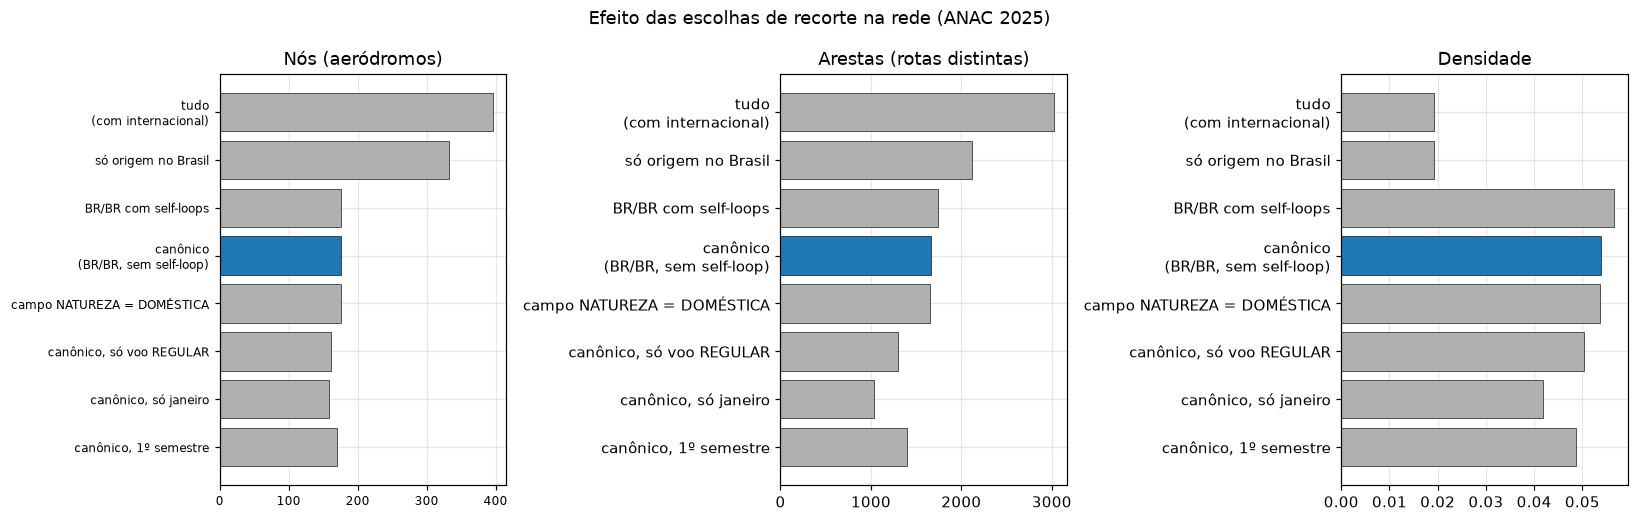

In [4]:

fig, eixos = plt.subplots(1, 3, figsize=(15, 4.8))
rotulos = tabela_recortes["recorte"].str.replace(" (", "\n(", regex=False)
cores = ["#b0b0b0"] * len(rotulos)
cores[3] = "#1f77b4"  # o recorte canônico fica destacado

for eixo, coluna, titulo in zip(eixos,
                                ["nos", "arestas", "densidade"],
                                ["Nós (aeródromos)", "Arestas (rotas distintas)", "Densidade"]):
    eixo.barh(rotulos, tabela_recortes[coluna], color=cores, edgecolor="black", linewidth=0.4)
    eixo.set_title(titulo)
    eixo.invert_yaxis()
    eixo.grid(axis="x", alpha=0.3)

eixos[0].tick_params(labelsize=8)
fig.suptitle("Efeito das escolhas de recorte na rede (ANAC 2025)", fontsize=12)
fig.tight_layout()
fig.savefig(FIGURAS / "01_efeito_dos_recortes.png", bbox_inches="tight")
plt.show()


**Leitura.**

- Entre a rede "tudo" (396 aeródromos, 3.020 rotas) e a doméstica canônica (176, 1.660)
  muda o objeto de estudo inteiro: a malha internacional tem outra geografia (conecta o
  Brasil ao exterior por poucos aeroportos), não responde à pergunta de contingência doméstica.
- O campo `NATUREZA` da ANAC classifica errado rotas internas (Curitiba→Campinas,
  Manaus→Belém, Galeão→Guarulhos aparecem como `INTERNACIONAL`): com 534 linhas e 6 rotas
  a menos, dá quase o mesmo (1.654 × 1.660) — mas o critério **geográfico** (`PAÍS`) é o
  verificável no dado linha a linha; o campo editorial da ANAC não é. Ficamos com `PAÍS`.
- **Self-loops**: 84 "rotas" com origem = destino. Não são ligações entre aeródromos
  (são contabilizações da própria base); ficam fora.
- **Só regular** derruba de 176 para 161 aeródromos: 15 aeródromos pequenos só aparecem por
  voo não regular/improdutivo. Optamos por manter todos (a rota existe, o voo decolou),
  registrando que esses voos são 32% das linhas, mas só 3,5% das decolagens
  (28.294 de 802.910).
- **Janela mensal**: um mês dá 158 nós e 1.039 rotas — 7,2% das decolagens do ano. A rede
  anual é a união de doze redes quase completas; qualquer leitura de "aeroporto com rota"
  é válida para o ano, não para cada mês (ver limitações).

## 3. Recorte canônico e a tabela de rotas

Recorte do projeto: **voo doméstico (Brasil→Brasil), `DECOLAGENS > 0`, sem self-loop,
agregado por par (origem, destino) somando os volumes do ano**. É essa tabela de arestas
que todos os notebooks seguem usando.

In [5]:

voos_domesticos = M.recortar(bruto)
rotas = M.agregar_rotas(voos_domesticos)
rotas.to_csv(RESULTADOS / "base_rotas_2025.csv", index=False)

print("rotas:", len(rotas), "| aeródromos:", len(set(rotas.origem) | set(rotas.destino)))
print("decolagens no ano:", int(rotas.decolagens.sum()))
print("passageiros pagos no ano:", int(rotas.passageiros.sum()))
rotas.sort_values("passageiros", ascending=False).head(8)[
    ["origem", "nome_origem", "uf_origem", "destino", "nome_destino", "uf_destino",
     "decolagens", "passageiros"]]


rotas: 1660 | aeródromos: 176
decolagens no ano: 802910
passageiros pagos no ano: 101082863


,origem,nome_origem,uf_origem,destino,nome_destino,uf_destino,decolagens,passageiros
1360,SBSP,SÃO PAULO,SP,SBRJ,RIO DE JANEIRO,RJ,18169.0,1969554.0
1213,SBRJ,RIO DE JANEIRO,RJ,SBSP,SÃO PAULO,SP,18163.0,1967057.0
128,SBBR,BRASÍLIA,DF,SBSP,SÃO PAULO,SP,8862.0,1174297.0
1325,SBSP,SÃO PAULO,SP,SBBR,BRASÍLIA,DF,8910.0,1163762.0
218,SBCF,CONFINS,MG,SBSP,SÃO PAULO,SP,8162.0,1028535.0
1327,SBSP,SÃO PAULO,SP,SBCF,CONFINS,MG,8166.0,1020314.0
1025,SBPA,PORTO ALEGRE,RS,SBSP,SÃO PAULO,SP,7885.0,1017930.0
1355,SBSP,SÃO PAULO,SP,SBPA,PORTO ALEGRE,RS,7927.0,1007258.0


In [6]:

por_regiao = (
    voos_domesticos.assign(regiao=voos_domesticos["AEROPORTO DE ORIGEM (REGIÃO)"])
    .groupby("regiao")
    .agg(aerodromos=("AEROPORTO DE ORIGEM (SIGLA)", "nunique"),
         decolagens=("DECOLAGENS", "sum"),
         passageiros=("PASSAGEIROS PAGOS", "sum"))
    .sort_values("decolagens", ascending=False)
)
por_regiao["share_decolagens"] = (por_regiao["decolagens"] / por_regiao["decolagens"].sum()).round(4)
por_regiao.to_csv(RESULTADOS / "por_regiao.csv")
por_regiao


,aerodromos,decolagens,passageiros,share_decolagens
regiao,,,,
SUDESTE,47,418368.0,51624621.0,0.5211
NORDESTE,42,146124.0,19503464.0,0.1820
SUL,25,100651.0,12487250.0,0.1254
CENTRO-OESTE,18,88655.0,12024964.0,0.1104
NORTE,44,49112.0,5442564.0,0.0612


## 4. Registro das decisões

Tabela para o README e para o vídeo: cada decisão, a alternativa que existia, o que foi
escolhido e por quê.

In [7]:

decisoes = pd.DataFrame([
    dict(decisao="Janela temporal", alternativas="ano de 2025 (arquivo inteiro) × mês × semestre",
         escolha="ano de 2025 (12 meses)",
         porque="pergunta é de conectividade estrutural; mês único perde 18 aeródromos (7,2% dos voos)",
         efeito="176 nós e 1.660 rotas; janeiro sozinho teria 158 e 1.039"),
    dict(decisao="Malha doméstica", alternativas="tudo × só origem BR × BR/BR",
         escolha="origem e destino no Brasil (PAÍS = BRASIL nas duas pontas)",
         porque="a pergunta é sobre a malha doméstica; o internacional conecta o país por poucos pontos",
         efeito="396 -> 176 nós; exclui 18% das decolagens"),
    dict(decisao="Campo de domesticidade", alternativas="PAÍS das pontas × NATUREZA (ANAC)",
         escolha="PAÍS das pontas",
         porque="NATUREZA marca 671 linhas internas como INTERNACIONAL (erro do campo); PAÍS é verificável",
         efeito="1.654 × 1.660 rotas; diferença de 6 rotas"),
    dict(decisao="Self-loops", alternativas="manter × remover origem = destino",
         escolha="remover (84 rotas, 963 linhas)",
         porque="aeroporto não é rota para si mesmo; inflaria grau, densidade e clustering",
         efeito="1.744 -> 1.660 arestas; densidade 0,0566 -> 0,0539"),
    dict(decisao="Tipo de voo", alternativas="todos os grupos × só REGULAR",
         escolha="todos os grupos (regular, não regular, improdutivo)",
         porque="a rota existiu; excluir derrubaria 15 aeródromos que só têm voo não regular",
         efeito="3,5% das decolagens são não regulares/improdutivas (32% das linhas)"),
    dict(decisao="Rota ativa", alternativas="DECOLAGENS > 0 × PASSAGEIROS > 0 × DECOLAGENS >= 0",
         escolha="DECOLAGENS > 0",
         porque="mede oferta (o voo aconteceu); há 5.586 linhas domésticas com 0 passageiro pago e decolagem > 0",
         efeito="37.988 linhas brutas -> 22.128 no recorte (23.091 antes de tirar self-loops)"),
])
decisoes.to_csv(RESULTADOS / "decisoes_recorte.csv", index=False)
decisoes


,decisao,alternativas,escolha,porque,efeito
0,Janela temporal,ano de 2025 (arquivo inteiro) × mês × semestre,ano de 2025 (12 meses),pergunta é de conectividade estrutural; mês ún...,176 nós e 1.660 rotas; janeiro sozinho teria 1...
1,Malha doméstica,tudo × só origem BR × BR/BR,origem e destino no Brasil (PAÍS = BRASIL nas ...,a pergunta é sobre a malha doméstica; o intern...,396 -> 176 nós; exclui 18% das decolagens
2,Campo de domesticidade,PAÍS das pontas × NATUREZA (ANAC),PAÍS das pontas,NATUREZA marca 671 linhas internas como INTERN...,1.654 × 1.660 rotas; diferença de 6 rotas
3,Self-loops,manter × remover origem = destino,"remover (84 rotas, 963 linhas)",aeroporto não é rota para si mesmo; inflaria g...,"1.744 -> 1.660 arestas; densidade 0,0566 -> 0,..."
4,Tipo de voo,todos os grupos × só REGULAR,"todos os grupos (regular, não regular, improdu...",a rota existiu; excluir derrubaria 15 aeródrom...,"3,5% das decolagens são não regulares/improdut..."
5,Rota ativa,DECOLAGENS > 0 × PASSAGEIROS > 0 × DECOLAGENS ...,DECOLAGENS > 0,mede oferta (o voo aconteceu); há 5.586 linhas...,37.988 linhas brutas -> 22.128 no recorte (23....


## Saídas deste notebook

- `resultados/base_rotas_2025.csv` — tabela de arestas do projeto (1.660 rotas).
- `resultados/tabela_recortes.csv` — efeito das escolhas de recorte.
- `resultados/por_regiao.csv` — volume por região de origem.
- `resultados/decisoes_recorte.csv` — registro das decisões.
- `figuras/01_efeito_dos_recortes.png`.

Segue em `02_rede.ipynb`: construção do digrafo, graus, matriz de adjacência, mapa,
BFS e amostragem (semanas 2 e 3).
